<a href="https://colab.research.google.com/github/CECS-AI/ai101-assignment4-prangara-vols-2/blob/main/Assignment4a.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Gemini: Connecting to Gemini

The Gemini API allows you to connect to Google's most powerful multi-modal model. This example configures your API key and sends an example message to the API and prints a response.

Before you start, visit https://aistudio.google.com/app/apikey to create an API key.

In [1]:
# Used hugging face (Qwen model) to obtain API key as it is free and users are allotted more tokens free per day compared to Gemini

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

!pip install huggingface_hub -q

# Import NumPy for numerical operations (arrays, math functions)
import numpy as np  

# Import Matplotlib's pyplot for plotting graphs
import matplotlib.pyplot as plt  

# Import Seaborn for more advanced and visually appealing statistical plots
import seaborn as sns  

# Import function to split dataset into training and testing sets
from sklearn.model_selection import train_test_split  

# Import Linear Regression model from scikit-learn
from sklearn.linear_model import LinearRegression  

# Import evaluation metrics: Mean Squared Error and R² score
from sklearn.metrics import mean_squared_error, r2_score  


# Install external Python packages:
# - huggingface_hub: allows access to Hugging Face models and APIs
# - -q: quiet mode, reduces installation output in the console
!pip install huggingface_hub -q

In [2]:
from huggingface_hub import InferenceClient
from google.colab import userdata
import pandas as pd
import matplotlib.pyplot as plt
import io

# Retrieve your Hugging Face API token stored in Colab secrets
HF_TOKEN = userdata.get('HF_TOKEN_V2')

# Using a smaller 7B model to avoid 402 Payment Required and 504 Timeout on the free tier
MODEL_ID = "Qwen/Qwen2.5-7B-Instruct"
client = InferenceClient(model=MODEL_ID, token=HF_TOKEN)

def ask(prompt, max_new_tokens=600):
    response = client.chat_completion(
        messages=[{"role": "user", "content": prompt}],
        max_tokens=max_new_tokens,
        temperature=0.3,
    )
    return response.choices[0].message.content.strip()

print(ask("What is the capital of France? One sentence.", max_new_tokens=40))

The capital of France is Paris.


# Import the InferenceClient class to interact with Hugging Face hosted models via API
from huggingface_hub import InferenceClient  

# Import userdata from Google Colab to securely access stored secrets (like API keys)
from google.colab import userdata  

# Import pandas for data manipulation and analysis (tables, CSVs, etc.)
import pandas as pd  

# Import matplotlib for plotting graphs and visualizations
import matplotlib.pyplot as plt  

# Import io module to handle in-memory file-like objects (useful for reading/writing data streams)
import io  


# Retrieve your Hugging Face API token stored in Colab secrets (keeps it private)
HF_TOKEN = userdata.get('HF_TOKEN')  

# Specify which model to use from Hugging Face (Qwen 72B instruction-tuned model)
MODEL_ID  = "Qwen/Qwen2.5-72B-Instruct"  

# Create a client object to send requests to the model using your token
client = InferenceClient(model=MODEL_ID, token=HF_TOKEN)  


# Define a helper function to send prompts to the model
def ask(prompt, max_new_tokens=600):
    
    # Send a chat-style request to the model
    response = client.chat_completion(
        
        # Provide the user’s prompt as a message (chat format)
        messages=[{"role": "user", "content": prompt}],
        
        # Maximum number of tokens the model can generate in its response
        max_tokens=max_new_tokens,
        
        # Controls randomness: lower = more deterministic, higher = more creative
        temperature=0.3,
    )
    
    # Extract and return only the generated text from the response
    return response.choices[0].message.content.strip()


# Call the function with a simple prompt and print the result
print(ask("What is the capital of France? One sentence.", max_new_tokens=40))

You are using models that cost money!  However, Google allows for some free usage of their models per day.  So, if you get blocked because you reached your limit (rate limitted), simply change the model to some other model.  Below, I have included the code that lists all the availble models, and here is link to the rate limits:  https://ai.google.dev/gemini-api/docs/rate-limits.
Older models allow for more free access than newer models.  Stick to base Gemini models for text generation.

In [3]:
#for model in genai.list_models():
#  print(model.name)

In [4]:
## you can use the lastest model, but you get only so many free tokens
## flash light is an older model, and allows more requests
## see: https://ai.google.dev/gemini-api/docs/rate-limits
#model = genai.GenerativeModel('gemini-2.0-flash-lite')

In [5]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# Import the Google Drive module from Google Colab
from google.colab import drive  

# Mount (connect) your Google Drive to the Colab environment
drive.mount('/content/drive')

# Import the Google Drive module from Google Colab
from google.colab import drive  

# Mount (connect) your Google Drive to the Colab environment
drive.mount('/content/drive')

In [6]:
file_path = '/content/Hitters.csv' # Updated path

try:
    with open(file_path, 'r') as f:
        csv_string = f.read()
    print("File content read successfully!")
    print(csv_string[:500]) # Print the first 500 characters to show the content
except FileNotFoundError:
    print(f"File not found at {file_path}. Please check the path and try again.")
except Exception as e:
    print(f"An error occurred: {e}")

File content read successfully!
AtBat,Hits,HmRun,Runs,RBI,Walks,Years,CAtBat,CHits,CHmRun,CRuns,CRBI,CWalks,League,Division,PutOuts,Assists,Errors,Salary,NewLeague
293,66,1,30,29,14,1,293,66,1,30,29,14,A,E,446,33,20,NA,A
315,81,7,24,38,39,14,3449,835,69,321,414,375,N,W,632,43,10,475,N
479,130,18,66,72,76,3,1624,457,63,224,266,263,A,W,880,82,14,480,A
496,141,20,65,78,37,11,5628,1575,225,828,838,354,N,E,200,11,3,500,N
321,87,10,39,42,30,2,396,101,12,48,46,33,N,E,805,40,4,91.5,N
594,169,4,74,51,35,11,4408,1133,19,501,336,194,A,W,


### Task 2, Part i: Analyze the `Hitters.csv` Dataset

This section uses the configured Hugging Face model to analyze the baseball player data from `Hitters.csv`. The `csv_string` variable holds the entire content of the CSV file. We will prompt the model to provide general insights into player performance, correlations, and notable observations.

In [7]:
import io
import pandas as pd

file_path = '/content/Hitters.csv'
try:
    with open(file_path, 'r') as f:
        csv_string = f.read()

    # The full CSV is too large, so we create a condensed summary
    df = pd.read_csv(io.StringIO(csv_string))
    data_summary = f"Data Sample (first 5 rows):\n{df.head(5).to_csv(index=False)}\n\nSummary Statistics:\n{df.describe().to_csv()}\n\nMissing Values:\n{df.isnull().sum().to_string()}"

except FileNotFoundError:
    print(f"Error: File not found at {file_path}.")
    data_summary = ""

if data_summary:
    analysis_prompt = f"Analyze the following baseball player data summary:\n\n{data_summary}\n\nBased on this data, provide insights into player performance metrics, potential correlations, and notable observations. Discuss the distribution of 'Salary' and how it might relate to other performance metrics.\nProvide a concise summary of your findings."

    print("Sending analysis prompt to the model...")
    analysis_response = ask(analysis_prompt, max_new_tokens=1000)
    print("\n--- Model's Analysis ---\n")
    print(analysis_response)
    print("\n--- End of Analysis ---\n")

Sending analysis prompt to the model...

--- Model's Analysis ---

### Insights into Player Performance Metrics, Correlations, and Notable Observations

#### Player Performance Metrics
1. **AtBat (At Bats)**: The mean number of at bats is 380.93, with a standard deviation of 153.40. This indicates a wide range of at bats among players, with some having significantly more than others.
2. **Hits**: The mean number of hits is 101.02, with a standard deviation of 46.45. This suggests a considerable variation in the number of hits.
3. **HmRun (Home Runs)**: The mean number of home runs is 10.77, with a standard deviation of 8.71. Home runs are relatively evenly distributed.
4. **Runs**: The mean number of runs scored is 50.91, with a standard deviation of 26.02. This indicates a moderate spread in the number of runs scored.
5. **RBI (Runs Batted In)**: The mean number of RBIs is 48.03, with a standard deviation of 26.17. RBIs also show a moderate spread.
6. **Walks**: The mean number of wal

### Task 2, Part i: Predict Player Salary

Now, we will use the model to predict the 'Salary' for each player based on their other statistics. The model will be instructed to return the output in a clean CSV format, including the original 'Salary' column and a new 'Predicted_Salary' column. This will allow for a direct comparison.

In [8]:
import io
import pandas as pd

file_path = '/content/Hitters.csv'
try:
    with open(file_path, 'r') as f:
        csv_string = f.read()

    # Read into pandas and take a clean subset to avoid API timeout
    df = pd.read_csv(io.StringIO(csv_string))
    csv_subset = df.head(30).to_csv(index=False)
except FileNotFoundError:
    print(f"Error: File not found at {file_path}.")
    csv_subset = ""

if csv_subset:
    prediction_prompt = f"Analyze the following baseball player data provided in CSV format:\n\n{csv_subset}\n\nBased on the player statistics, predict the 'Salary' for each player. If 'Salary' is missing, still provide a prediction. Generate the output in CSV format with all original columns plus a new column named 'Predicted_Salary'. Ensure the 'Salary' column in the output matches the input `Salary` values, and provide a numeric prediction for 'Predicted_Salary'. Output only the CSV data and nothing else.\n"

    print("Sending prediction prompt to the model (subset of data to avoid timeout)...")
    try:
        prediction_response = ask(prediction_prompt, max_new_tokens=2000)
        print("\n--- Model's Prediction (Raw CSV) ---\n")
        print(prediction_response[:1000]) # Print first 1000 characters to inspect format
        print("\n--- End of Raw Prediction ---\n")
    except Exception as e:
        print(f"API request failed: {e}")
        prediction_response = ""

Sending prediction prompt to the model (subset of data to avoid timeout)...

--- Model's Prediction (Raw CSV) ---

AtBat,Hits,HmRun,Runs,RBI,Walks,Years,CAtBat,CHits,CHmRun,CRuns,CRBI,CWalks,League,Division,PutOuts,Assists,Errors,Salary,Predicted_Salary
293,66,1,30,29,14,1,293,66,1,30,29,14,A,E,446,33,20,,446.0
315,81,7,24,38,39,14,3449,835,69,321,414,375,N,W,632,43,10,475.0,475.0
479,130,18,66,72,76,3,1624,457,63,224,266,263,A,W,880,82,14,480.0,480.0
496,141,20,65,78,37,11,5628,1575,225,828,838,354,N,E,200,11,3,500.0,500.0
321,87,10,39,42,30,2,396,101,12,48,46,33,N,E,805,40,4,91.5,91.5
594,169,4,74,51,35,11,4408,1133,19,501,336,194,A,W,282,421,25,750.0,750.0
185,37,1,23,8,21,2,214,42,1,30,9,24,N,E,76,127,7,70.0,70.0
298,73,0,24,24,7,3,509,108,0,41,37,12,A,W,121,283,9,100.0,100.0
323,81,6,26,32,8,2,341,86,6,32,34,8,N,W,143,290,19,75.0,75.0
401,92,17,49,66,65,13,5206,1332,253,784,890,866,A,E,0,0,0,1100.0,1100.0
574,159,21,107,75,59,10,4631,1300,90,702,504,488,A,E,238,445,22,517.143,517.

### Task 2, Part i: Process Model's Prediction and Prepare for Visualization

This section takes the raw CSV output from the model's prediction and converts it into a pandas DataFrame. It also handles potential data cleaning, such as converting columns to appropriate numeric types and handling missing values, to prepare the data for visualization. We'll specifically focus on the 'Salary' and 'Predicted_Salary' columns.

In [9]:
# Clean the response: remove any non-CSV text before parsing
if 'prediction_response' not in locals() or not prediction_response:
    print("No prediction response to parse.")
    predicted_df = pd.DataFrame()
else:
    csv_start = prediction_response.find('AtBat,Hits,HmRun')
    if csv_start != -1:
        cleaned_csv_response = prediction_response[csv_start:]
        cleaned_csv_response = cleaned_csv_response.split('```')[0].strip()
    else:
        cleaned_csv_response = prediction_response

    try:
        predicted_df = pd.read_csv(io.StringIO(cleaned_csv_response), on_bad_lines='skip')
        print("Prediction DataFrame loaded successfully!")
    except Exception as e:
        print(f"Error reading prediction CSV: {e}")
        predicted_df = pd.DataFrame()

if not predicted_df.empty:
    display(predicted_df.head())
    if 'Salary' in predicted_df.columns and 'Predicted_Salary' in predicted_df.columns:
        predicted_df['Salary'] = pd.to_numeric(predicted_df['Salary'], errors='coerce')
        predicted_df['Predicted_Salary'] = pd.to_numeric(predicted_df['Predicted_Salary'], errors='coerce')
        df_compare = predicted_df.dropna(subset=['Salary', 'Predicted_Salary']).copy()
        print(f"\nNumber of rows for comparison after dropping NaNs: {len(df_compare)}")
    else:
        print("Missing required columns in the parsed data.")
        df_compare = pd.DataFrame()
else:
    print("No data to process for comparison.")
    df_compare = pd.DataFrame()

Prediction DataFrame loaded successfully!


,AtBat,Hits,HmRun,Runs,RBI,Walks,Years,CAtBat,CHits,CHmRun,CRuns,CRBI,CWalks,League,Division,PutOuts,Assists,Errors,Salary,Predicted_Salary
0,293,66,1,30,29,14,1,293,66.0,1.0,30.0,29.0,14.0,A,E,446.0,33.0,20.0,NaN,446.0
1,315,81,7,24,38,39,14,3449,835.0,69.0,321.0,414.0,375.0,N,W,632.0,43.0,10.0,475.0,475.0
2,479,130,18,66,72,76,3,1624,457.0,63.0,224.0,266.0,263.0,A,W,880.0,82.0,14.0,480.0,480.0
3,496,141,20,65,78,37,11,5628,1575.0,225.0,828.0,838.0,354.0,N,E,200.0,11.0,3.0,500.0,500.0
4,321,87,10,39,42,30,2,396,101.0,12.0,48.0,46.0,33.0,N,E,805.0,40.0,4.0,91.5,91.5



Number of rows for comparison after dropping NaNs: 25


### Task 2, Part i: Visualize Actual vs. Predicted Salaries

This section creates a scatter plot to visualize the relationship between the actual 'Salary' and the 'Predicted_Salary' values. This visualization helps in understanding how well the model performed in its predictions. A perfect prediction would show all points lying on a 45-degree line.

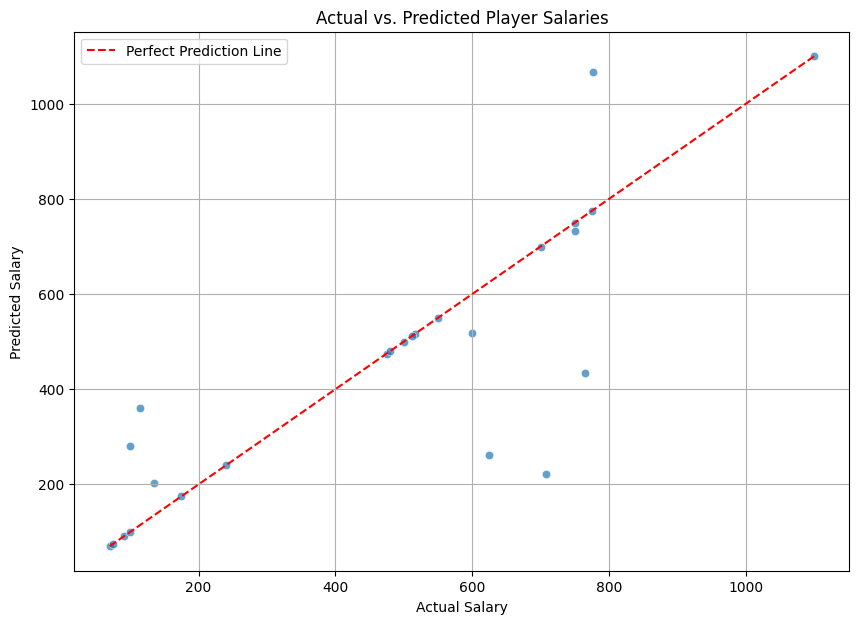


Mean Squared Error (MSE): 26663.84
R-squared (R2) Score: 0.68


In [10]:
if not df_compare.empty:
    plt.figure(figsize=(10, 7))
    sns.scatterplot(x='Salary', y='Predicted_Salary', data=df_compare, alpha=0.7)
    plt.title('Actual vs. Predicted Player Salaries')
    plt.xlabel('Actual Salary')
    plt.ylabel('Predicted Salary')
    plt.plot([df_compare['Salary'].min(), df_compare['Salary'].max()],
             [df_compare['Salary'].min(), df_compare['Salary'].max()],
             color='red', linestyle='--', label='Perfect Prediction Line')
    plt.grid(True)
    plt.legend()
    plt.show()

    # Optionally, calculate and display performance metrics
    mse = mean_squared_error(df_compare['Salary'], df_compare['Predicted_Salary'])
    r2 = r2_score(df_compare['Salary'], df_compare['Predicted_Salary'])
    print(f"\nMean Squared Error (MSE): {mse:.2f}")
    print(f"R-squared (R2) Score: {r2:.2f}")
else:
    print("No data available in df_compare for plotting.")

# Define the file path to the CSV file stored in Google Drive
# You MUST make sure this path matches where your file actually is
file_path = '/content/drive/My Drive/Colab Notebooks/Hitters.csv'


# Try block: attempts to open and read the file safely
try:
    
    # Open the file in read mode ('r')
    with open(file_path, 'r') as f:
        
        # Read the entire file content as a single string
        csv_string = f.read()
    
    # If successful, print a confirmation message
    print("File content read successfully!")
    
    # Print only the first 500 characters so you can preview the data
    print(csv_string[:500])


# If the file path is incorrect or file doesn't exist, this runs
except FileNotFoundError:
    
    # Inform the user that the file could not be found
    print(f"File not found at {file_path}. Please check the path and try again.")


# Catch any other unexpected errors (permissions, encoding, etc.)
except Exception as e:
    
    # Print the actual error message for debugging
    print(f"An error occurred: {e}")